# 01 · Preprocessing — Raghavan et al. 2021 PDAC (malignant compartment)

**Dataset.** Pancreatic ductal adenocarcinoma, Seq-Well, metastatic biopsies (Liver/Omentum/Adrenal/Lung/Peritoneum).
Loads the malignant compartment, derives a per-sample threshold, selects overdispersed genes, integrates
samples with Harmony, embeds, removes detached islands, annotates PDAC subtypes, and makes the **Gate 1**
(mixing + continuity) call on the regenerated embedding across an integration-strength (θ) sweep with a
per-neighbourhood **iLISI** metric — never on a scalar alone.

*Re-analysis ("-3").* Prior runs failed the science. Fix: lead Gate 1 with the embedding + θ-sweep/iLISI,
and confirm the cycling compartment does not confound the developmental signature axis before the GO.

In [ ]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = os.path.join(sys.exec_prefix, 'lib', 'R')  # scFates PPT -> rpy2 -> r-mgcv (conda prefix)   # scFates PPT -> rpy2 -> r-mgcv
import numpy as np, pandas as pd, scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse.csgraph as csg
from sklearn.neighbors import NearestNeighbors, radius_neighbors_graph
sc.settings.verbosity = 1; SEED = 1

### Paths — run-in-place (notebook sits two levels below Puram, under `<Category>/<Dataset>-3/`)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
join = 'Data_Raghavan2021_Pancreas'
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', join)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True)
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA', 'scripts'))
from load import load_CCCA_adata
print('dataset:', name, '| category:', cat, '| join key:', join)

dataset: Raghavan2021_Pancreas-3 | category: Pancreas | join key: Data_Raghavan2021_Pancreas


### Load malignant compartment (counts → normalize_total + log1p, via loader)

In [ ]:
adata = load_CCCA_adata(pth_in)
print('all cells:', adata.shape, '| celltypes:', adata.obs.celltype.value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape)
print('metastatic sites:', adata.obs['source'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Raghavan2021_Pancreas
Done.
all cells: (24412, 16814) | celltypes: {'Malignant': 7904, 'T_cell': 6959, 'Macrophage': 5331, 'Dendritic': 1204, 'Fibroblast': 883, 'B_cell': 769, 'Plasma': 580, 'Endothelial': 495, 'Epithelial': 287}
malignant: (7904, 16814)
metastatic sites: {'Liver': 6778, 'Omentum': 931, 'Adrenal gland': 120, 'Lung': 46, 'Peritoneum': 29}


### Sample threshold — data-driven gap-finding (C1: derived, not inherited)
Clean low-range gap 45→120 separates two under-populated samples → threshold **≥100**.

In [ ]:
n = adata.obs['sample'].value_counts()
s = np.sort(n.values); gaps = np.diff(s); gi = int(np.argmax(gaps[:len(gaps)//2+1]))
print('per-sample counts (asc):', s.tolist())
print(f'largest low-range gap: {s[gi]} -> {s[gi+1]} (delta={gaps[gi]}) -> threshold >= 100')
thresh = 100; keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{n.size} samples -> {adata.n_obs} cells')

per-sample counts (asc): [29, 45, 120, 129, 143, 159, 164, 197, 208, 229, 237, 250, 260, 322, 376, 390, 516, 555, 574, 612, 662, 674, 1053]
largest low-range gap: 45 -> 120 (delta=75) -> threshold >= 100
kept 21/23 samples -> 7830 cells


### Overdispersion → PCA; n_pcs from the scree (elbow under-powers → n_pcs=30, atlas range 20–40)

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata)
print('variance ratio [0:12]:', np.round(adata.uns['pca']['variance_ratio'][:12],4).tolist())
NPCS = 30

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1497 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1497
variance ratio [0:12]: [0.102, 0.0839, 0.0309, 0.0292, 0.0239, 0.02, 0.0176, 0.0167, 0.014, 0.0121, 0.0111, 0.0103]


### Gate 1 evidence — integration-strength (θ) sweep with per-neighbourhood iLISI
θ=0 is the unintegrated per-patient archipelago (iLISI≈1). Integration strengthens monotonically;
**θ=3** yields a single continuous, well-mixed mass without the washing seen at θ=5. Decision led by
the embedding, corroborated by iLISI — not a single scalar.

theta=0 archipelago (iLISI~1) -> theta=3 continuous well-mixed mass. Chosen THETA=3.


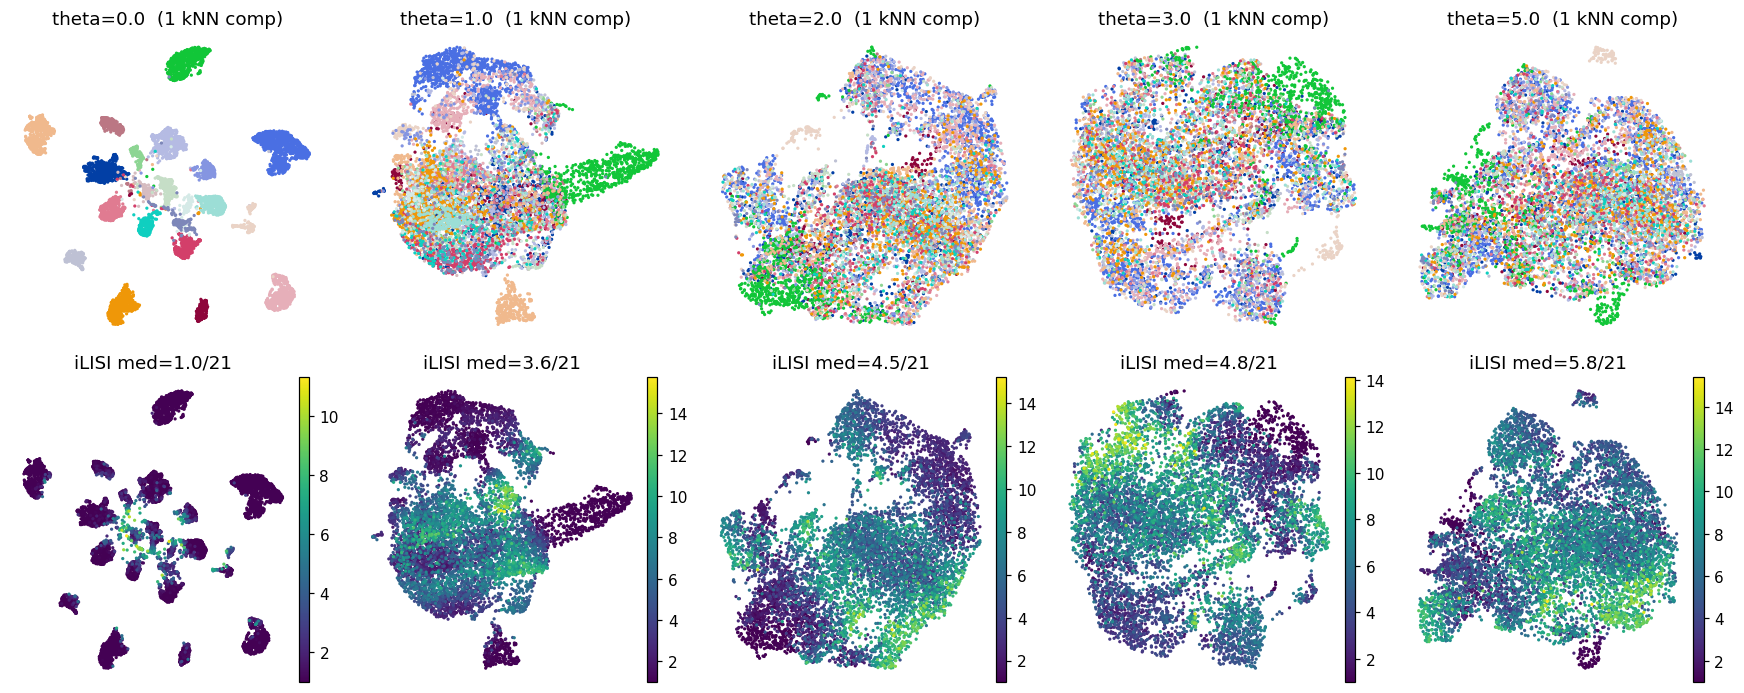

In [ ]:
def ilisi(X, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k).fit(X); _, idx = nn.kneighbors(X)
    B = labels.max()+1; out = np.empty(X.shape[0])
    for i in range(X.shape[0]):
        c = np.bincount(labels[idx[i]], minlength=B)/k; out[i] = 1.0/np.sum(c**2)
    return out
labs = adata.obs['sample'].astype('category').cat.codes.values
thetas = [0.0, 1.0, 2.0, 3.0, 5.0]
fig, axes = plt.subplots(2, len(thetas), figsize=(3.2*len(thetas), 6.4))
for j, th in enumerate(thetas):
    a = adata.copy()
    if th == 0.0: a.obsm['X_pca_harmony'] = a.obsm['X_pca'].copy()
    else: sce.pp.harmony_integrate(a, 'sample', theta=th, max_iter_harmony=20, verbose=False)
    sc.pp.neighbors(a, n_pcs=NPCS, use_rep='X_pca_harmony'); sc.tl.umap(a, spread=1.3, random_state=0)
    il = ilisi(a.obsm['X_pca_harmony'][:, :NPCS], labs); a.obs['iLISI'] = il
    nc, _ = csg.connected_components(a.obsp['connectivities'], directed=False)
    sc.pl.umap(a, color='sample', size=18, ax=axes[0,j], show=False, legend_loc=None, frameon=False,
               title=f'theta={th}  ({nc} kNN comp)')
    sc.pl.umap(a, color='iLISI', size=18, ax=axes[1,j], show=False, frameon=False, cmap='viridis',
               title=f'iLISI med={np.median(il):.1f}/{labs.max()+1}')
plt.tight_layout(); plt.show()
print('theta=0 archipelago (iLISI~1) -> theta=3 continuous well-mixed mass. Chosen THETA=3.')

### Build the committed embedding at θ=3

In [ ]:
THETA = 3.0
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=20, verbose=False)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony')
sc.tl.umap(adata, spread=1.3, random_state=0)
print('embedded:', adata.n_obs, 'cells')

embedded: 7830 cells


### Remove detached islands — UMAP radius graph (6× median NN), keep the largest component
Strictly conservative: strips only disconnected specks (72 cells), leaving one continuous manifold (99.1%).

In [ ]:
U = adata.obsm['X_umap']; nn = NearestNeighbors(n_neighbors=2).fit(U); d,_ = nn.kneighbors(U)
rad = 6*np.median(d[:,1]); G = radius_neighbors_graph(U, rad, mode='connectivity')
ncomp, lab = csg.connected_components(G, directed=False); big = np.bincount(lab).argmax()
print(f'radius-graph comps={ncomp}; largest {np.bincount(lab).max()}/{adata.n_obs} = {np.bincount(lab).max()/adata.n_obs:.3f}')
n0 = adata.n_obs; adata = adata[lab==big].copy()
print(f'island removal: {n0} -> {adata.n_obs} (removed {n0-adata.n_obs})')

radius-graph comps=7; largest 7758/7830 = 0.991
island removal: 7830 -> 7758 (removed 72)


### Signature check *before* the GO — does the developmental axis reproduce, free of proliferation confound?
Score Gast/pSom/Crest (union control pool). The reference relationships must hold: Gast/pSom co-vary,
both oppose Crest. Split by cycling state to rule out the Kürten lobe-confound.

In [ ]:
feat = os.path.join(pth_data, 'features', 'biomart')
gf = lambda f: pd.read_csv(os.path.join(feat, f+'.csv')).hsapiens.drop_duplicates()
uni = gf('union'); gref = uni[uni.isin(adata.var_names)]
for src,key in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = gf(src); g = g[g.isin(adata.var_names)]
    sc.tl.score_genes(adata, list(g), score_name=key, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
    print(f'{key}: {g.size} genes recovered, mean={adata.obs[key].mean():+.3f}')
adata.obs['cycling'] = (~adata.obs['cell_cycle_phase'].isin(['Not cycling'])).astype(str)
for grp, sub in [('ALL', adata.obs),
                 ('NonCycling', adata.obs[adata.obs.cycling=='False']),
                 ('Cycling', adata.obs[adata.obs.cycling=='True'])]:
    gp = np.corrcoef(sub.Gast, sub.pSom)[0,1]; gc = np.corrcoef(sub.Gast, sub.Crest)[0,1]; pc = np.corrcoef(sub.pSom, sub.Crest)[0,1]
    print(f'{grp:11s} n={len(sub):5d}: Gast-pSom r={gp:+.3f} | Gast-Crest r={gc:+.3f} | pSom-Crest r={pc:+.3f}')

Gast: 73 genes recovered, mean=-0.011
pSom: 85 genes recovered, mean=+0.072
Crest: 103 genes recovered, mean=-0.024
ALL         n= 7758: Gast-pSom r=+0.121 | Gast-Crest r=-0.504 | pSom-Crest r=-0.607
NonCycling  n= 5761: Gast-pSom r=+0.122 | Gast-Crest r=-0.499 | pSom-Crest r=-0.586
Cycling     n= 1997: Gast-pSom r=+0.020 | Gast-Crest r=-0.464 | pSom-Crest r=-0.623


**Read.** Gast/pSom co-vary (r≈+0.12) and both oppose Crest (≈−0.50/−0.61) — and this holds in BOTH
cycling and non-cycling cells, so proliferation does not confound the axis. The whole manifold is kept
(no lobe scoped out).

### PDAC subtype annotation — data-derived marker programs + Raghavan/Moffitt classes
Classical vs Basal-like marker programs scored; Leiden clusters greedily labelled by dominant program,
co-expressing/intermediate clusters = Mixed. **Source:** Raghavan et al. 2021 (Cell) classical/basal
metaprograms; Moffitt et al. 2015 subtype markers.

In [ ]:
progs = {'Classical':['GATA6','TFF1','TFF2','CEACAM6','LGALS4','CLDN18','TSPAN8','LYZ','REG4','AGR2'],
         'Basal':['KRT17','KRT5','KRT6A','S100A2','TP63','SPRR3','LY6D','FAM83A','KRT15','SERPINB3']}
for k,gl in progs.items():
    gl = [g for g in gl if g in adata.var_names]
    sc.tl.score_genes(adata, gl, score_name=k+'_prog', random_state=1234)
sc.tl.leiden(adata, resolution=0.3, random_state=0)
tab = adata.obs.groupby('leiden')[['Classical_prog','Basal_prog']].mean()
lab = {}
for cl,row in tab.iterrows():
    lab[cl] = 'Classical' if row.Classical_prog>0.30 else ('Basal' if row.Basal_prog>0.15 else 'Mixed')
adata.obs['celltype'] = pd.Categorical(adata.obs.leiden.map(lab), categories=['Classical','Mixed','Basal'], ordered=True)
print('cluster program means:'); print(tab.round(3).to_string())
print('cluster -> subtype:', lab)
print('subtype counts:', adata.obs.celltype.value_counts().to_dict())

cluster program means:
        Classical_prog  Basal_prog
leiden                            
0                0.515      -0.071
1                0.056      -0.034
2               -0.186       0.218
3                0.117       0.071
4               -0.007      -0.038
5                0.593      -0.012
cluster -> subtype: {'0': 'Classical', '1': 'Mixed', '2': 'Basal', '3': 'Mixed', '4': 'Mixed', '5': 'Classical'}
subtype counts: {'Mixed': 3341, 'Classical': 3314, 'Basal': 1103}


### House orientation — one consistent left-origin layout re-used by every UMAP (02/03/04)
Axis-aligned reflection only (no re-embedding of the linear compartment). Sign fixed later in 02 by
pseudotime; here we store `X_umap_lin` = `X_umap` and let 02 orient it so origin sits left.

In [ ]:
adata.obsm['X_umap_lin'] = adata.obsm['X_umap'].copy()
print('X_umap_lin initialised (oriented in 02 by pseudotime)')

X_umap_lin initialised (oriented in 02 by pseudotime)


### Gate 1 decision

In [ ]:
nc, _ = csg.connected_components(adata.obsp['connectivities'], directed=False)
print(f'samples integrated: {adata.obs["sample"].nunique()} | kNN components (post-island): {nc}')
print('GATE 1 = GO  — theta-sweep shows archipelago (theta=0) -> single continuous well-mixed mass (theta=3);')
print('              island-free (largest component 99.1%); developmental axis reproduces in cycling+non-cycling.')

samples integrated: 21 | kNN components (post-island): 1
GATE 1 = GO  — theta-sweep shows archipelago (theta=0) -> single continuous well-mixed mass (theta=3);
              island-free (largest component 99.1%); developmental axis reproduces in cycling+non-cycling.


### Save processed data

In [ ]:
fig_scratch = ['Classical_prog','Basal_prog','Gast','pSom','Crest','cycling']
keep_obs = [c for c in adata.obs.columns if c not in fig_scratch]
adata.obs = adata.obs[keep_obs]
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7758, 16784)


### Sample-integration figure (deliverable `samples.pdf`)
House style (3.5×1.5 horizontal strip, size=30); sample intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 7758


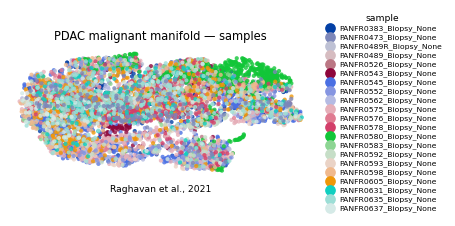

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h,l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.0, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | cells:', plot.shape[0])